In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_excel("sample_-_superstore.xls")
print("Dataset Loaded Successfully!")

Dataset Loaded Successfully!


In [4]:
df['Order Date'] = pd.to_datetime(df['Order Date'])

df['Year'] = df['Order Date'].dt.year
df['Month'] = df['Order Date'].dt.month

monthly_sales = df.groupby(
    ['Year', 'Month']
)['Sales'].sum().reset_index()

monthly_sales['Year-Month'] = (
    monthly_sales['Year'].astype(str) + '-' +
    monthly_sales['Month'].astype(str).str.zfill(2)
)

print(monthly_sales)


    Year  Month        Sales Year-Month
0   2023      1   14518.0550    2023-01
1   2023      2    4519.8920    2023-02
2   2023      3   56933.9090    2023-03
3   2023      4   28295.3450    2023-04
4   2023      5   26319.7670    2023-05
5   2023      6   34669.4796    2023-06
6   2023      7   33946.3930    2023-07
7   2023      8   28918.3385    2023-08
8   2023      9   82670.4288    2023-09
9   2023     10   32413.3390    2023-10
10  2023     11   78826.9567    2023-11
11  2023     12   72008.3085    2023-12
12  2024      1   18461.9156    2024-01
13  2024      2   11951.4110    2024-02
14  2024      3   39978.6280    2024-03
15  2024      4   34195.2085    2024-04
16  2024      5   30246.9465    2024-05
17  2024      6   24797.2920    2024-06
18  2024      7   28765.3250    2024-07
19  2024      8   37057.0042    2024-08
20  2024      9   64627.0460    2024-09
21  2024     10   31407.1335    2024-10
22  2024     11   75972.5635    2024-11
23  2024     12   75532.5572    2024-12


### Monthly Trend Visualization

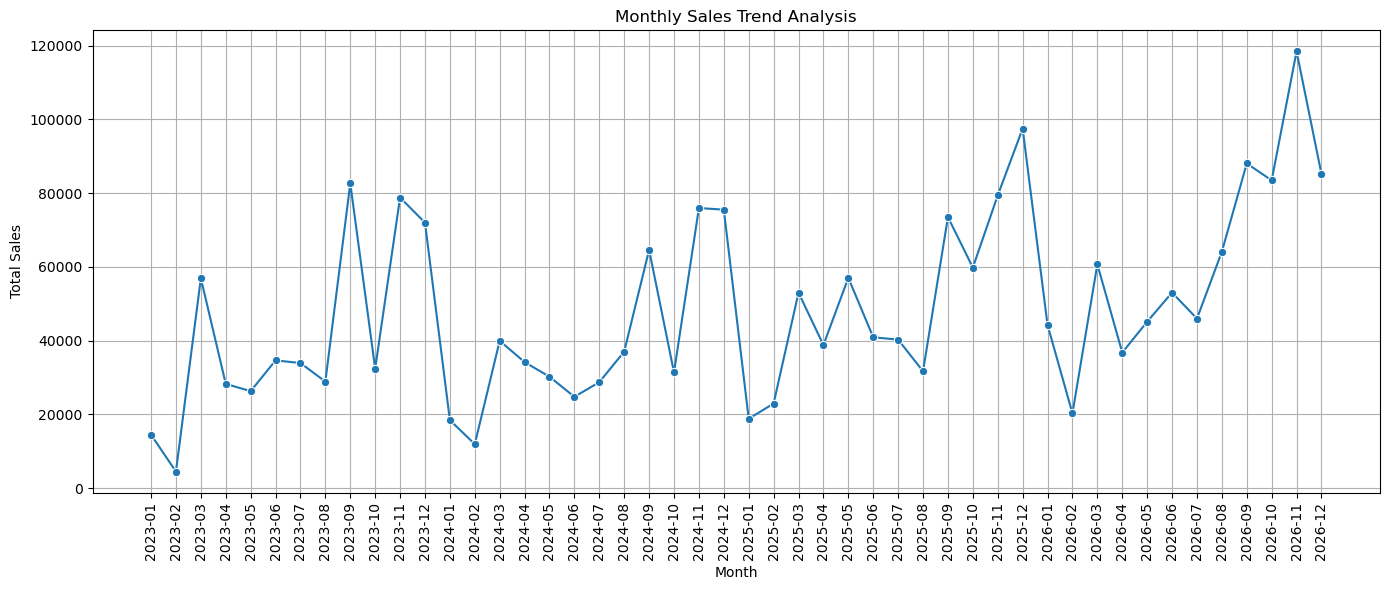

In [5]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_sales,
    x='Year-Month',
    y='Sales',
    marker='o'
)

plt.title('Monthly Sales Trend Analysis')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()


### Find highest and lowest sales months

In [8]:
highest_month = monthly_sales.loc[
    monthly_sales['Sales'].idxmax()
]

lowest_month = monthly_sales.loc[
    monthly_sales['Sales'].idxmin()
]

print("Highest Sales Month:")
print(highest_month)

print("\nLowest Sales Month:")
print(lowest_month)


Highest Sales Month:
Year                2026
Month                 11
Sales         118454.505
Year-Month       2026-11
Name: 46, dtype: object

Lowest Sales Month:
Year              2023
Month                2
Sales         4519.892
Year-Month     2023-02
Name: 1, dtype: object


### Calculate monthly sales growth

In [9]:
monthly_sales['Sales Growth (%)'] = (
    monthly_sales['Sales'].pct_change() * 100
)

print(monthly_sales)


    Year  Month        Sales Year-Month  Sales Growth (%)
0   2023      1   14518.0550    2023-01               NaN
1   2023      2    4519.8920    2023-02        -68.867097
2   2023      3   56933.9090    2023-03       1159.629854
3   2023      4   28295.3450    2023-04        -50.301419
4   2023      5   26319.7670    2023-05         -6.981989
5   2023      6   34669.4796    2023-06         31.724113
6   2023      7   33946.3930    2023-07         -2.085657
7   2023      8   28918.3385    2023-08        -14.811749
8   2023      9   82670.4288    2023-09        185.875445
9   2023     10   32413.3390    2023-10        -60.792100
10  2023     11   78826.9567    2023-11        143.192954
11  2023     12   72008.3085    2023-12         -8.650148
12  2024      1   18461.9156    2024-01        -74.361409
13  2024      2   11951.4110    2024-02        -35.264513
14  2024      3   39978.6280    2024-03        234.509691
15  2024      4   34195.2085    2024-04        -14.466278
16  2024      